# TP 2 : Apprentissage Profond avec TensorFlow / Keras
**Module :** Technologies IA — **ENSA Fès** — ILIA2

Ce notebook contient le code complet des deux exercices (MNIST puis Fashion-MNIST) ainsi que les réponses aux questions du TP.

> **Remarque :** les valeurs chiffrées (précisions, pertes) varient légèrement d'une exécution à l'autre. Les réponses ci-dessous donnent les ordres de grandeur attendus ; vérifiez-les avec vos propres sorties après avoir exécuté les cellules.

**Prérequis :** `pip install tensorflow matplotlib numpy seaborn scikit-learn`

# Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST)
## 1. Import des bibliothèques

In [1]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

I0000 00:00:1792930127.173681   10890 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792930128.229290   10890 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792930131.095747   10890 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


In [ ]:
pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━ 479.7/572.9 MB 6.0 MB/s eta 0:00:16:18

### Réponses aux questions

**1. Différence entre TensorFlow et Keras ?**
TensorFlow est le *moteur de calcul* (tenseurs, calcul sur CPU/GPU, différentiation automatique, déploiement). Keras est l'*API haut niveau* (`tf.keras`) construite par-dessus : elle permet de définir, entraîner et évaluer un réseau en quelques lignes, sans écrire le calcul du gradient à la main.

**2. Rôle de `Flatten` ?**
Elle transforme chaque image 2D (28×28) en un vecteur 1D de 784 valeurs, format attendu par les couches `Dense`. Elle n'a aucun paramètre à apprendre.

**3. Version de TensorFlow ?**
Elle est affichée par la cellule ci-dessus (`tf.__version__`) ; elle dépend de votre machine.

**4. Rôle de `Sequential` et `Dense` ?**
- `Sequential` : modèle formé d'une *pile linéaire de couches* (la sortie d'une couche est l'entrée de la suivante).
- `Dense` : couche *entièrement connectée* : chaque neurone est relié à tous les neurones de la couche précédente (calcul `activation(W·x + b)`).

## 2. Chargement et préparation du dataset

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Type des pixels avant normalisation :", x_train.dtype)
print("Valeurs min/max avant normalisation :", x_train.min(), x_train.max())

# Normalisation
x_train = x_train / 255.0
x_test = x_test / 255.0

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("Taille d'une image :", x_train[0].shape, "| type après normalisation :", x_train.dtype)
print("Valeurs min/max après normalisation :", x_train.min(), x_train.max())

Type des pixels avant normalisation : uint8
Valeurs min/max avant normalisation : 0 255
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
Taille d'une image : (28, 28) | type après normalisation : float64
Valeurs min/max après normalisation : 0.0 1.0


### Réponses aux questions

**1. Pourquoi normaliser les pixels ?**
Pour ramener les valeurs de [0, 255] à [0, 1]. Les entrées ont alors une échelle homogène et petite, ce qui stabilise les gradients, évite les poids qui explosent et **accélère la convergence** de l'optimiseur.

**2. Taille et type d'une image ?**
28 × 28 pixels, niveaux de gris (1 canal). Type d'origine : `uint8` (entiers de 0 à 255) ; après division par `255.0` : `float64`.

**3. Nombre d'exemples d'entraînement ?**
**60 000** images d'entraînement (`x_train.shape = (60000, 28, 28)`) et 10 000 pour le test, soit 70 000 au total.

## 3. Visualisation d'échantillons

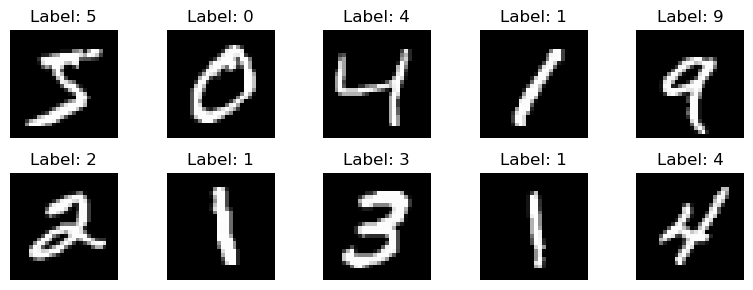

In [3]:
plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

**À faire :** les 10 premiers chiffres de MNIST d'entraînement sont `5, 0, 4, 1, 9, 2, 1, 3, 1, 4`. Les labels affichés au-dessus de chaque image doivent correspondre au chiffre dessiné.

### Réponses aux questions

**1. Commande pour modifier le nombre d'images affichées ?**
Changer la borne de `range(10)` (ex. `range(20)`) et adapter la grille `plt.subplot(lignes, colonnes, i+1)` (ex. `plt.subplot(4, 5, i+1)`).

**2. Rôle de `cmap='gray'` ?**
C'est la *carte de couleurs* : elle affiche les valeurs scalaires en niveaux de gris (0 = noir, 1 = blanc). Sans elle, matplotlib utilise la palette par défaut (viridis).

**3. Utilité de cette étape ?**
Vérifier visuellement la qualité des données (images lisibles, labels cohérents, bon format, pas d'inversion ni de corruption) **avant** d'entraîner : c'est une étape clé d'exploration (EDA).

## 4. Construction du modèle

In [4]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

E0000 00:00:1792931644.448410   10890 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Réponses aux questions

**1. Nombre de paramètres ?**
- `Dense(128)` : 784 × 128 + 128 = **100 480**
- `Dense(10)` : 128 × 10 + 10 = **1 290**
- Total : **101 770** paramètres entraînables (`Flatten` : 0).

**2. Activation de la couche de sortie ? Pourquoi ?**
**Softmax** : elle transforme les 10 sorties en une *distribution de probabilités* (valeurs entre 0 et 1, de somme 1). La classe prédite est celle de plus forte probabilité : adapté à la classification multiclasse à classes exclusives.

**3. Différence ReLU / Softmax ?**
- **ReLU** `f(x) = max(0, x)` : activation des couches *cachées*, appliquée neurone par neurone, non linéaire, simple et peu sujette à la disparition du gradient.
- **Softmax** `f(xᵢ) = eˣⁱ / Σ eˣʲ` : activation de la *couche de sortie*, elle agit sur tout le vecteur et produit des probabilités qui somment à 1.

## 5. Compilation du modèle

In [5]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Réponses aux questions

**1. Qu'est-ce qu'un optimiseur ?**
L'algorithme qui met à jour les poids à partir des gradients calculés par rétropropagation, afin de réduire la perte (SGD, RMSprop, Adam…). Adam adapte le pas d'apprentissage pour chaque paramètre.

**2. Pourquoi une fonction de perte ?**
Elle mesure l'écart entre la prédiction et la vérité sous forme d'un nombre **différentiable** : c'est la quantité que l'entraînement cherche à minimiser et dont on calcule le gradient.

**3. Que se passe-t-il si on la change ?**
Le modèle optimise un autre critère. Une perte inadaptée (ex. MSE pour de la classification) donne un apprentissage plus lent ou moins performant ; une perte incompatible avec le format des labels provoque une erreur (ex. `categorical_crossentropy` avec des labels entiers, alors qu'ici on utilise `sparse_categorical_crossentropy` car `y_train` contient des entiers 0–9).

**4. Conséquence d'un mauvais optimiseur ?**
Convergence très lente, oscillations ou divergence (pas trop grand), blocage dans un mauvais minimum / plateau, ou nécessité d'un réglage fin du learning rate.

**5. Différence `loss` / `metrics` ?**
La `loss` est ce que l'on **optimise** (différentiable, sert à la rétropropagation). Les `metrics` servent seulement à **évaluer/suivre** la performance de façon lisible (accuracy) et n'influencent pas l'apprentissage.

## 6. Entraînement du modèle

In [6]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5


W0000 00:00:1792931682.567533   10890 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


1862/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9255 - loss: 0.2597

W0000 00:00:1792931689.529015   10890 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9258 - loss: 0.2587 - val_accuracy: 0.9614 - val_loss: 0.1337
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9665 - loss: 0.1123 - val_accuracy: 0.9705 - val_loss: 0.0914
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9764 - loss: 0.0773 - val_accuracy: 0.9730 - val_loss: 0.0890
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9829 - loss: 0.0582 - val_accuracy: 0.9763 - val_loss: 0.0755
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9862 - loss: 0.0446 - val_accuracy: 0.9765 - val_loss: 0.0784


**À observer :** la précision d'entraînement augmente d'époque en époque (≈ 92 % → ≈ 98,5 %) et la précision de validation suit la même tendance en se stabilisant autour de 97–98 %.

### Réponses aux questions

**1. Qu'est-ce qu'une époque ?**
Un passage complet sur *tout* le jeu d'entraînement. Avec 60 000 images et `batch_size=32`, une époque = 1 875 itérations (mises à jour des poids).

**2. Pourquoi un jeu de validation ?**
Pour mesurer la capacité de généralisation pendant l'entraînement sur des données non utilisées pour ajuster les poids, détecter le surapprentissage et régler les hyperparamètres. *(Remarque : ici, on utilise `x_test` comme validation, donc ce jeu n'est plus strictement « jamais vu » pour le choix du modèle ; en pratique on préfère `validation_split`.)*

**3. Et avec 50 époques ?**
La précision d'entraînement approche 100 % et la perte d'entraînement continue de baisser, mais la perte de validation finit par remonter : c'est du **surapprentissage**. Le temps de calcul augmente sans gain réel de précision sur le test (on peut utiliser `EarlyStopping`).

## 7. Évaluation du modèle

In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9765 - loss: 0.0784 
Test accuracy: 0.9765
Test loss: 0.0784


### Réponses aux questions

**1. Précision finale ?**
Typiquement **≈ 97,5 % à 98 %** sur le jeu de test (valeur exacte affichée ci-dessus : `Test accuracy`).

**2. Pourquoi la précision du test est souvent inférieure à celle d'entraînement ?**
Le modèle a ajusté ses poids sur les données d'entraînement (il peut en partie les « mémoriser »), alors que les données de test lui sont inconnues : l'écart traduit l'erreur de généralisation.

**3. Que faire en cas de surapprentissage ?**
Plus de données ou *data augmentation*, `Dropout`, régularisation L1/L2, modèle plus simple, *early stopping*, moins d'époques, *batch normalization*, ou architecture mieux adaptée (CNN).

## 8. Visualisation des performances

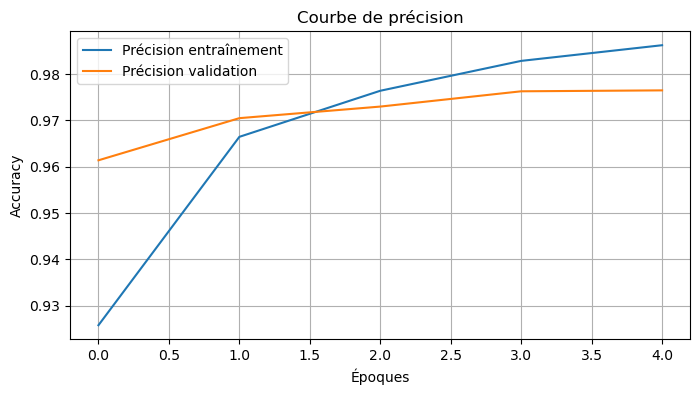

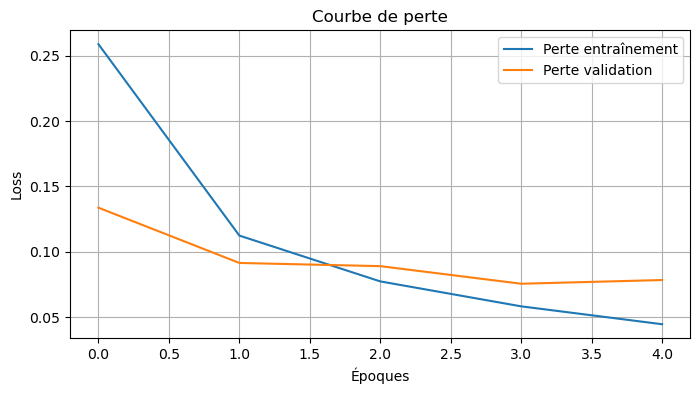

In [8]:
# Courbes de précision
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Courbes de perte (demandées dans le rapport)
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Perte entraînement')
plt.plot(history.history['val_loss'], label='Perte validation')
plt.title('Courbe de perte')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Réponses aux questions

**1. Que remarquez-vous ?**
Les deux courbes de précision montent rapidement dès les premières époques puis se stabilisent ; la précision d'entraînement finit légèrement au-dessus de celle de validation. Les courbes de perte baissent de façon symétrique.

**2. Comment détecter visuellement un surapprentissage ?**
La précision d'entraînement continue de monter alors que celle de validation stagne ou baisse ; la perte de validation remonte alors que la perte d'entraînement continue de diminuer : un écart croissant entre les deux courbes.

**3. Stratégies pour y remédier ?**
Dropout, régularisation, *early stopping*, data augmentation, réduction de la taille du modèle, plus de données.

**4. Que faire si les courbes divergent ?**
Arrêter l'entraînement au meilleur point (`EarlyStopping(restore_best_weights=True)`), ajouter de la régularisation / du Dropout, simplifier le modèle ou augmenter les données ; vérifier aussi le learning rate.

## 9. Prédictions et visualisation

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step  


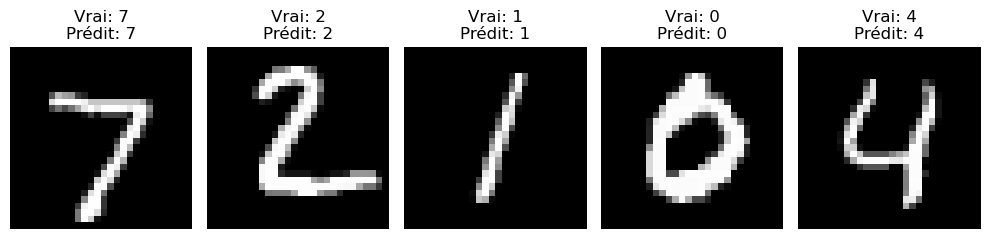

In [9]:
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Nombre d'erreurs : 235 sur 10000


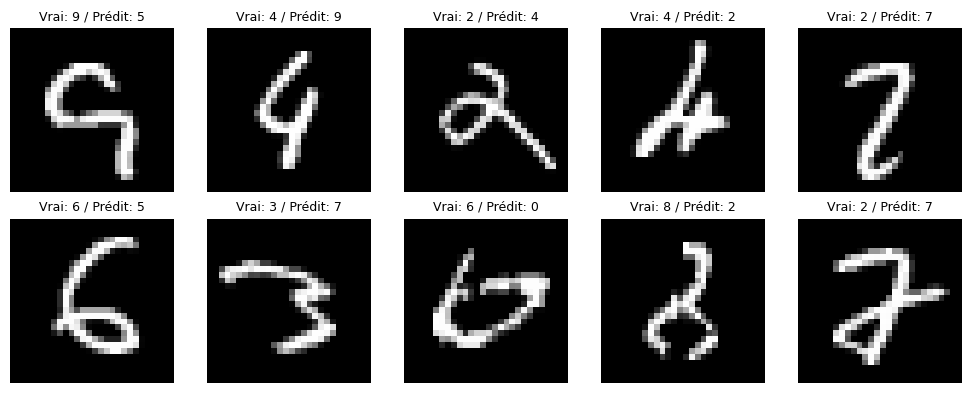

In [10]:
# Bonus : affichage de quelques erreurs de prédiction
y_pred_mnist = np.argmax(predictions, axis=1)
errors = np.where(y_pred_mnist != y_test)[0]
print(f"Nombre d'erreurs : {len(errors)} sur {len(y_test)}")

plt.figure(figsize=(10, 4))
for k, i in enumerate(errors[:10]):
    plt.subplot(2, 5, k + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]} / Prédit: {y_pred_mnist[i]}", fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

### Réponses aux questions

**1. Le modèle fait-il des erreurs ? Sur quelles images ?**
Sur les 5 premières images du test (`7, 2, 1, 0, 4`) il se trompe rarement voire jamais, mais sur les 10 000 images il commet environ 200 à 250 erreurs (≈ 2 %), surtout sur des chiffres mal écrits ou ambigus (4/9, 3/5, 7/1, 2/7…) — voir la cellule « Bonus ».

**2. Comment expliquer une prédiction erronée ?**
Écriture ambiguë ou atypique, chiffres ressemblants, bruit, décalage ou inclinaison du chiffre ; un réseau dense ignore la structure spatiale (il traite les pixels comme un vecteur) et n'est pas invariant aux translations.

**3. Technique pour améliorer la précision ?**
Un **CNN** (convolutions + pooling) qui exploite la structure 2D et atteint > 99 % sur MNIST ; aussi Dropout, plus de couches/neurones, data augmentation, réglage des hyperparamètres.

## Travail demandé 

> À adapter avec vos propres valeurs obtenues.

- **Interprétation :** le réseau dense à une couche cachée (128 neurones, 101 770 paramètres) atteint environ 97–98 % de précision en seulement 5 époques. L'écart train/validation reste faible, donc peu de surapprentissage à ce stade.
- **Difficultés :** installation de TensorFlow / compatibilité de version, choix de la perte adaptée au format des labels (`sparse_categorical_crossentropy` pour des entiers), utilisation de `x_test` comme jeu de validation.
- **Améliorations :** ajouter une seconde couche cachée et du `Dropout`, tester d'autres activations / optimiseurs / `batch_size` / learning rate, utiliser `EarlyStopping`, et surtout passer à un CNN.

---
# Exercice 2 : Classification d'images avec Fashion-MNIST
## Chargement via Keras

In [11]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

# Pour la reproductibilité
tf.random.set_seed(42)

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

## Étape 1 – Exploration du jeu de données
### A. Dimensions et types

In [12]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type des données :", X_train.dtype)
print("Valeurs des pixels : min =", X_train.min(), ", max =", X_train.max())

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type des données : uint8
Valeurs des pixels : min = 0 , max = 255


### B. Visualisation d'exemples

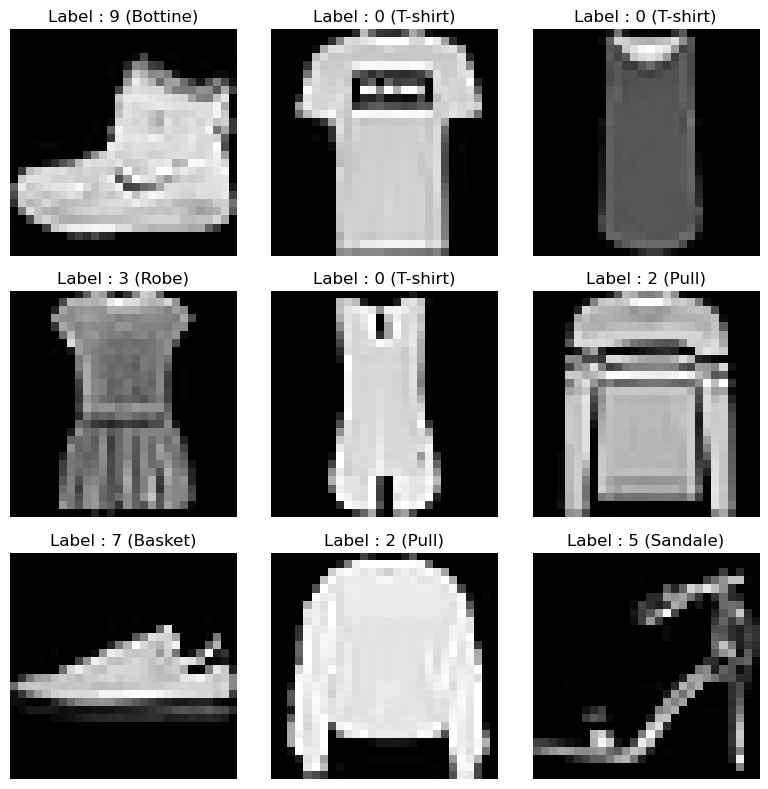

In [13]:
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]} ({class_names[y_train[i]]})")
    plt.axis('off')
plt.tight_layout()
plt.show()

**Question : que remarquez-vous sur la nature des données et la taille des images ?**
Ce sont des images de vêtements en niveaux de gris, de petite taille (28 × 28 = 784 pixels), au format `uint8` (0–255), avec une seule couche de couleur. Le jeu est équilibré (6 000 images par classe en train), centré et de faible résolution. Contrairement à MNIST, les classes sont visuellement plus proches (T-shirt/chemise/pull) et donc plus difficiles à séparer.

## Étape 2 – Prétraitement des données

In [14]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1 (+ conversion en float)
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Exemple de label :", y_train[0], "->", y_train_cat[0])

Exemple de label : 9 -> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


### Réponses aux questions

**1. Pourquoi normaliser ?**
Pour avoir des entrées de même échelle et de faible amplitude : apprentissage plus stable et plus rapide (gradients mieux conditionnés), moins sensible à l'initialisation et au learning rate.

**2. Importance du one-hot encoding ?**
Il représente chaque classe par un vecteur de 10 composantes (un seul « 1 »), compatible avec la sortie `softmax` et la perte `categorical_crossentropy`. Il évite que le modèle interprète les labels comme des quantités ordonnées (ex. « 9 » n'est pas « plus grand » que « 2 »), ce qui n'a pas de sens pour des catégories.

## Étape 3 – Création d'un modèle dense (ANN)

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Nombre de paramètres : 784×128+128 = 100 480 ; 128×64+64 = 8 256 ; 64×10+10 = 650 → **109 386** paramètres.

In [16]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10


W0000 00:00:1792931859.290490   10890 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


362/375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7741 - loss: 0.6378 

W0000 00:00:1792931862.487236   10890 cpu_allocator_impl.cc:82] Allocation of 37632000 exceeds 10% of free system memory.


375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7761 - loss: 0.6320 - val_accuracy: 0.8419 - val_loss: 0.4423
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8481 - loss: 0.4260 - val_accuracy: 0.8572 - val_loss: 0.3973
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8615 - loss: 0.3820 - val_accuracy: 0.8655 - val_loss: 0.3666
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8694 - loss: 0.3586 - val_accuracy: 0.8682 - val_loss: 0.3553
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8740 - loss: 0.3418 - val_accuracy: 0.8738 - val_loss: 0.3465
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8791 - loss: 0.3291 - val_accuracy: 0.8686 - val_loss: 0.3511
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8828 - loss: 0.3150 - val_accuracy: 0.8796 - val_loss: 0.3322
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8861 - loss: 0.3073 - val_accuracy: 0.8764 - val_

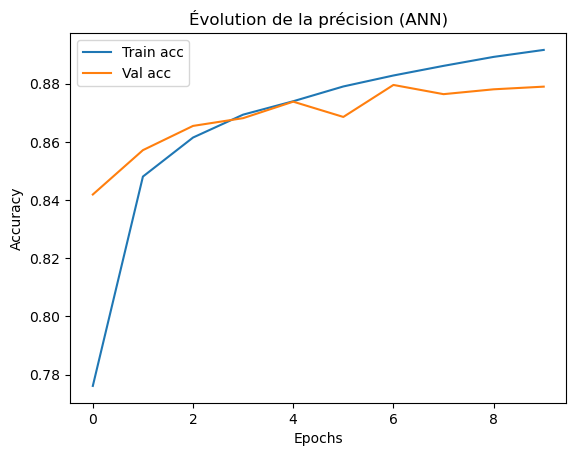

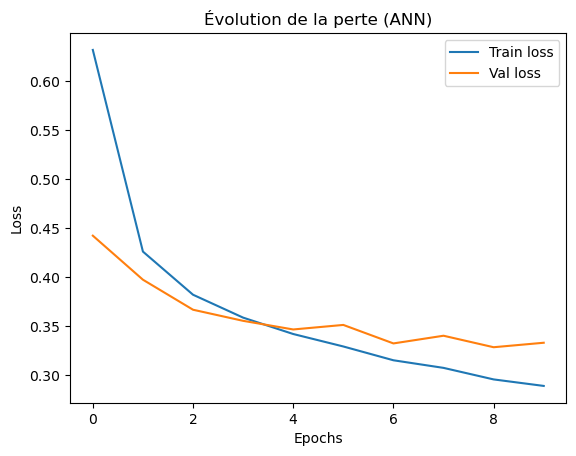

In [17]:
# Visualisation
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.legend()
plt.title('Évolution de la perte (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

### Réponses aux questions

**1. Pourquoi ReLU ici ?**
Simple et rapide à calculer, non linéaire (permet d'apprendre des relations complexes), et elle limite le problème de disparition du gradient (gradient = 1 pour x > 0), d'où une convergence plus rapide que sigmoïde/tanh.

**2. Différence `accuracy` / `val_accuracy` ?**
`accuracy` est calculée sur les données d'entraînement (80 % du train) ; `val_accuracy` sur les 20 % mis de côté (`validation_split=0.2`) que le modèle n'utilise pas pour ajuster ses poids : elle mesure la généralisation.

**3. Et avec 50 époques ?**
La précision d'entraînement continue de monter (> 95 %) tandis que la précision de validation plafonne (≈ 88–89 %) et la perte de validation remonte : surapprentissage. Il vaut mieux utiliser `EarlyStopping` ou plus de régularisation.

### Évaluation finale

In [18]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)

 73/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8780 - loss: 0.3270 

W0000 00:00:1792931912.252955   10890 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8709 - loss: 0.3593
Précision sur le test set : 0.8708999752998352


Précision attendue pour l'ANN : **≈ 87–89 %**.

## Étape 4 — Introduction aux fonctions d'activation

{'sigmoid': 0.859416663646698, 'tanh': 0.871749997138977, 'relu': 0.8768333196640015, 'LeakyReLU': 0.8733333349227905}


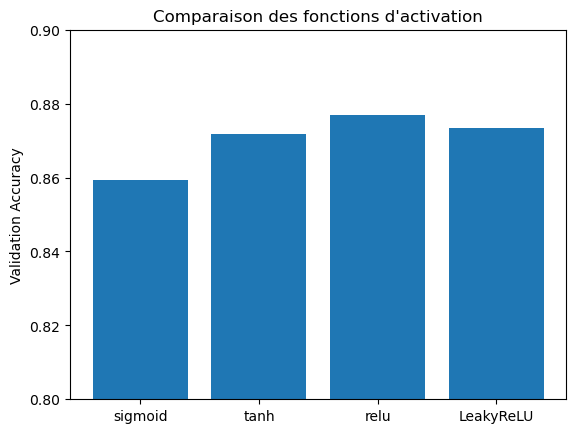

In [20]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])

    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# Leaky ReLU
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128, validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

print(results)

plt.bar(results.keys(), results.values())
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.ylim(0.8, 0.9)
plt.show()

### Réponses aux questions

**1. Quelle fonction donne les meilleurs résultats ?**
En général **ReLU** et **LeakyReLU** obtiennent les meilleures précisions de validation (≈ 87–88 % en 5 époques), `tanh` est proche et **sigmoïde** est un peu en retrait (convergence plus lente). Vérifiez avec votre dictionnaire `results` : les écarts sont faibles et varient d'une exécution à l'autre.

**2. Pourquoi sigmoïde et tanh sont moins utilisées dans les couches cachées ?**
Elles *saturent* : pour de grandes valeurs positives ou négatives leur dérivée tend vers 0, d'où le problème de **disparition du gradient** (surtout dans les réseaux profonds), un apprentissage lent ; elles sont aussi plus coûteuses (exponentielles). Sigmoïde n'est pas centrée sur zéro, contrairement à tanh.

**3. À quoi sert LeakyReLU ?**
Elle laisse passer une petite pente (`α x`, ici α = 0,1) pour les entrées négatives au lieu de renvoyer 0. Cela évite le problème des « neurones morts » de ReLU (neurones bloqués à 0 qui ne reçoivent plus de gradient).

## Étape 5 : Modèle CNN (Convolutional Neural Network)

In [21]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

# Reshape pour ajouter la dimension "canal"
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - accuracy: 0.7704 - loss: 0.6393 - val_accuracy: 0.8500 - val_loss: 0.4170
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 54ms/step - accuracy: 0.8555 - loss: 0.4000 - val_accuracy: 0.8775 - val_loss: 0.3423
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.8745 - loss: 0.3476 - val_accuracy: 0.8868 - val_loss: 0.3147
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 27s 72ms/step - accuracy: 0.8848 - loss: 0.3160 - val_accuracy: 0.8919 - val_loss: 0.2997
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 30s 81ms/step - accuracy: 0.8911 - loss: 0.2942 - val_accuracy: 0.8951 - val_loss: 0.2893
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.8986 - loss: 0.2778 - val_accuracy: 0.8987 - val_loss: 0.2752
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.9037 - loss: 0.2612 - val_accuracy: 0.9006 - val_loss: 0.2652
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 64ms/step - accuracy: 0.9099 - loss: 0.2446 - 

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8993 - loss: 0.2735
Précision CNN sur test set : 0.8992999792098999


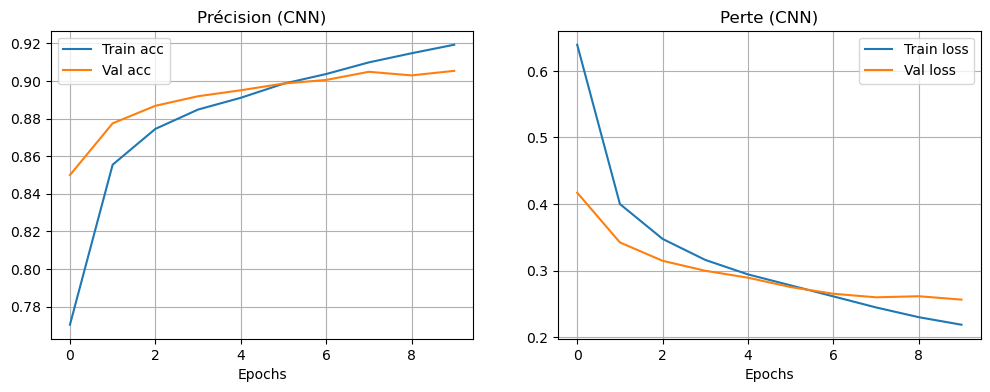

In [23]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)

# Courbes d'apprentissage du CNN
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_cnn.history['accuracy'], label='Train acc')
ax[0].plot(history_cnn.history['val_accuracy'], label='Val acc')
ax[0].set_title('Précision (CNN)'); ax[0].set_xlabel('Epochs'); ax[0].legend(); ax[0].grid(True)
ax[1].plot(history_cnn.history['loss'], label='Train loss')
ax[1].plot(history_cnn.history['val_loss'], label='Val loss')
ax[1].set_title('Perte (CNN)'); ax[1].set_xlabel('Epochs'); ax[1].legend(); ax[1].grid(True)
plt.show()

Paramètres du CNN : 320 + 18 496 + 204 928 + 1 290 = **225 034**. Précision attendue sur le test : **≈ 91–92 %**.

### Réponses aux questions

**1. Différence entre ANN et CNN ?**
L'ANN (couches `Dense`) aplatit l'image et relie chaque pixel à chaque neurone : beaucoup de paramètres et aucune notion de voisinage. Le CNN applique des **filtres convolutifs partagés** sur de petites zones : il conserve la structure spatiale 2D et apprend des motifs locaux (bords, textures, formes) de plus en plus abstraits.

**2. Pourquoi le CNN est-il généralement meilleur ?**
Il exploite la structure spatiale, le partage des poids (moins de paramètres par rapport à la taille de l'image), l'invariance partielle aux translations (grâce à la convolution et au pooling), et construit une hiérarchie de caractéristiques.

**3. Rôle du Pooling ?**
`MaxPooling2D((2,2))` réduit la taille spatiale des cartes de caractéristiques (divise par 2), ce qui diminue le nombre de paramètres et le calcul, rend le modèle plus robuste aux petites translations/déformations et limite le surapprentissage.

## Étape 6 — Visualisation des performances (matrice de confusion)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


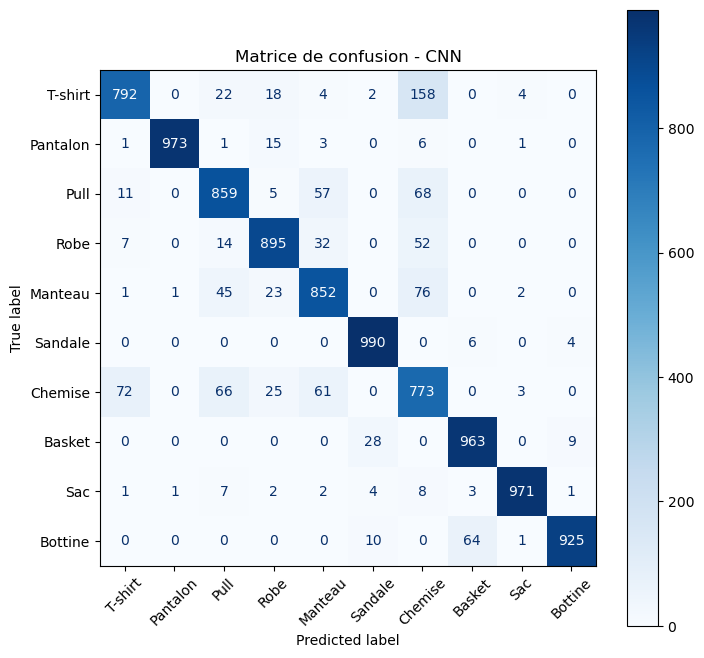

              precision    recall  f1-score   support

     T-shirt       0.89      0.79      0.84      1000
    Pantalon       1.00      0.97      0.99      1000
        Pull       0.85      0.86      0.85      1000
        Robe       0.91      0.90      0.90      1000
     Manteau       0.84      0.85      0.85      1000
     Sandale       0.96      0.99      0.97      1000
     Chemise       0.68      0.77      0.72      1000
      Basket       0.93      0.96      0.95      1000
         Sac       0.99      0.97      0.98      1000
     Bottine       0.99      0.93      0.95      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues", display_labels=class_names,
    xticks_rotation=45, ax=ax
)
plt.title("Matrice de confusion - CNN")
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names))

### Réponses aux questions

**1. Quelles classes sont le plus souvent confondues ?**
Surtout **Chemise ↔ T-shirt / Pull / Manteau** (la classe « Chemise » a la plus faible précision), puis **Pull ↔ Manteau**, et dans une moindre mesure **Basket ↔ Bottine ↔ Sandale** : ces classes ont des silhouettes très proches en 28×28.

**2. Comment réduire ces erreurs ?**
Un CNN plus profond avec `BatchNormalization`, plus d'époques avec `EarlyStopping`, data augmentation, réglage du learning rate, ensemble de modèles, ou *transfer learning* ; augmenter la résolution des images si possible.

## Étape 7 : Data Augmentation

In [25]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

history_aug = cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10


I0000 00:00:1792933190.536948   10890 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


469/469 ━━━━━━━━━━━━━━━━━━━━ 32s 67ms/step - accuracy: 0.8603 - loss: 0.3849 - val_accuracy: 0.8861 - val_loss: 0.2970
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 30s 63ms/step - accuracy: 0.8801 - loss: 0.3261 - val_accuracy: 0.8983 - val_loss: 0.2729
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 32s 68ms/step - accuracy: 0.8841 - loss: 0.3128 - val_accuracy: 0.9010 - val_loss: 0.2791
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 63ms/step - accuracy: 0.8897 - loss: 0.2984 - val_accuracy: 0.9072 - val_loss: 0.2621
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - accuracy: 0.8937 - loss: 0.2930 - val_accuracy: 0.9014 - val_loss: 0.2647
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - accuracy: 0.8953 - loss: 0.2833 - val_accuracy: 0.9087 - val_loss: 0.2544
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 59ms/step - accuracy: 0.8980 - loss: 0.2772 - val_accuracy: 0.9090 - val_loss: 0.2508
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - accuracy: 0.8991 - loss: 0.2700 - val_accurac

In [26]:
test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN (après data augmentation) :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9138 - loss: 0.2371
Précision CNN (après data augmentation) : 0.9138000011444092


> **Note :** `ImageDataGenerator` est déprécié dans les versions récentes de Keras (un avertissement peut s'afficher), mais reste fonctionnel. L'alternative moderne : des couches `RandomRotation`, `RandomZoom`, `RandomFlip` placées au début du modèle. De plus, ce second `fit` *continue* l'entraînement du même modèle `cnn` (déjà entraîné 10 époques) ; pour une comparaison équitable, recréez un modèle neuf avant ce `fit`.

### Réponses aux questions

**1. Intérêt de la Data Augmentation ?**
Elle génère des variantes (rotation, zoom, symétrie…) des images d'entraînement : le jeu de données « effectif » est plus grand et plus varié, le modèle devient plus robuste et généralise mieux (moins de surapprentissage).

**2. Quelles transformations sont les plus efficaces pour ce dataset ?**
Les petites rotations (≈ 10°), les petits zooms et surtout le **retournement horizontal** (un pull ou une chaussure reste la même classe en miroir) sont pertinents. En revanche, le retournement **vertical** ou les grandes rotations ne sont pas adaptés (un vêtement est toujours présenté à l'endroit, une robe à l'envers n'est pas réaliste).

## Travail demandé — analyse personnelle (Exercice 2)

> À adapter avec vos propres résultats.

- **Interprétation :** l'ANN atteint ≈ 88 % ; le CNN améliore ce score à ≈ 91–92 % grâce à l'exploitation de la structure spatiale. Les erreurs se concentrent sur les classes visuellement proches (Chemise, T-shirt, Pull, Manteau). ReLU/LeakyReLU convergent mieux que sigmoïde.
- **Difficultés :** gestion des formes (`reshape` pour ajouter le canal), choix de la perte selon l'encodage des labels (one-hot → `categorical_crossentropy`), dépréciation de `ImageDataGenerator`, temps d'entraînement sans GPU.
- **Améliorations :** `BatchNormalization`, davantage de couches convolutives, `EarlyStopping`, réglage de learning rate / `batch_size`, data augmentation avec couches Keras, architectures plus avancées (ResNet, transfer learning).